# Tugas Akhir 07 (TA-07): Implementasi Q-Learning untuk Skenario RL Diskrit
**Mata Praktikum:** Pembelajaran Mesin    
**Nama:** Muhammad Fajar Ramdani  
**NIM:** 301240036

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

class CourierGridEnv:
    def __init__(self):
        self.grid_size = 5
        self.state_size = self.grid_size * self.grid_size  # 25 states (0-24)
        self.action_size = 4  # 0: Atas, 1: Bawah, 2: Kiri, 3: Kanan

        self.start_pos = (0, 0)
        self.goal_pos = (4, 4)
        # Titik kemacetan / blokade jalan (Obstacle)
        self.obstacles = [(1, 1), (1, 3), (2, 3), (3, 1), (3, 2)]
        self.reset()

    def reset(self):
        self.agent_pos = self.start_pos
        return self._pos_to_state(self.agent_pos)

    def _pos_to_state(self, pos):
        return pos[0] * self.grid_size + pos[1]

    def _state_to_pos(self, state):
        return (state // self.grid_size, state % self.grid_size)

    def step(self, action):
        row, col = self.agent_pos

        if action == 0:    # Atas
            next_row, next_col = row - 1, col
        elif action == 1:  # Bawah
            next_row, next_col = row + 1, col
        elif action == 2:  # Kiri
            next_row, next_col = row, col - 1
        elif action == 3:  # Kanan
            next_row, next_col = row, col + 1

        # Cek batas dinding luar grid
        if next_row < 0 or next_row >= self.grid_size or next_col < 0 or next_col >= self.grid_size:
            return self._pos_to_state(self.agent_pos), -5, False

        self.agent_pos = (next_row, next_col)
        new_state = self._pos_to_state(self.agent_pos)

        # Cek status terminal (Goal atau Obstacle)
        if self.agent_pos == self.goal_pos:
            return new_state, 100, True
        elif self.agent_pos in self.obstacles:
            return new_state, -50, True
        else:
            return new_state, -1, False

env = CourierGridEnv()
print(f"Environment berhasil dibuat! Total State: {env.state_size}, Total Action: {env.action_size}")

Environment berhasil dibuat! Total State: 25, Total Action: 4


In [20]:
def train_q_learning(env, alpha=0.8, gamma=0.9, episodes=2000, max_steps=100,
                     epsilon_start=1.0, min_epsilon=0.01, decay_rate=0.003):
    q_table = np.zeros((env.state_size, env.action_size))
    rewards_per_episode = []
    epsilon = epsilon_start

    for episode in range(episodes):
        state = env.reset()
        total_reward = 0

        for step in range(max_steps):
            # Strategi Epsilon-Greedy
            if np.random.uniform(0, 1) < epsilon:
                action = np.random.randint(0, env.action_size)  # Eksplorasi
            else:
                action = np.argmax(q_table[state, :])           # Eksploitasi

            # Eksekusi aksi di lingkungan
            new_state, reward, done = env.step(action)

            # Pembaruan Q-Table menggunakan Persamaan Bellman
            best_next_q = np.max(q_table[new_state, :])
            td_target = reward + gamma * best_next_q
            q_table[state, action] = (1 - alpha) * q_table[state, action] + alpha * td_target

            state = new_state
            total_reward += reward

            if done:
                break

        # Epsilon Decay
        epsilon = min_epsilon + (epsilon_start - min_epsilon) * np.exp(-decay_rate * episode)
        rewards_per_episode.append(total_reward)

    return q_table, rewards_per_episode

# Latih model utama
np.random.seed(42)
q_table_main, rewards_main = train_q_learning(env, alpha=0.8, gamma=0.9, episodes=2000)

# Tampilkan Q-Table hasil pelatihan
df_qtable = pd.DataFrame(
    q_table_main,
    columns=['Atas (0)', 'Bawah (1)', 'Kiri (2)', 'Kanan (3)'],
    index=[f'State {i} {env._state_to_pos(i)}' for i in range(env.state_size)]
)
print("Q-Table Akhir Setelah 2.000 Episode:")
display(df_qtable.round(2))

Q-Table Akhir Setelah 2.000 Episode:


,Atas (0),Bawah (1),Kiri (2),Kanan (3)
"State 0 (0, 0)",33.35,32.62,33.35,42.61
"State 1 (0, 1)",38.61,-50.00,37.35,48.46
"State 2 (0, 2)",44.46,42.61,42.61,54.95
"State 3 (0, 3)",50.95,-50.00,48.46,62.17
"State 4 (0, 4)",58.17,70.19,54.95,58.17
"State 5 (1, 0)",37.35,27.43,28.56,-50.00
"State 6 (1, 1)",0.00,0.00,0.00,0.00
"State 7 (1, 2)",48.46,36.86,-50.00,-50.00
"State 8 (1, 3)",0.00,0.00,0.00,0.00
"State 9 (1, 4)",62.17,79.10,-50.00,66.19


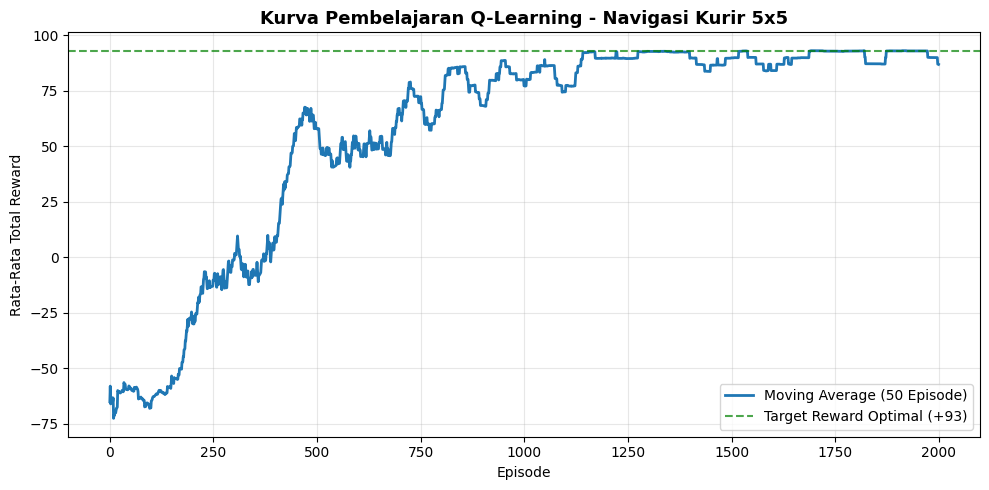

In [21]:
window_size = 50
rewards_ma = pd.Series(rewards_main).rolling(window=window_size, min_periods=1).mean()

plt.figure(figsize=(10, 5))
plt.plot(rewards_ma, color='#1f77b4', linewidth=2, label=f'Moving Average ({window_size} Episode)')
plt.axhline(y=93, color='green', linestyle='--', alpha=0.7, label='Target Reward Optimal (+93)')
plt.title('Kurva Pembelajaran Q-Learning - Navigasi Kurir 5x5', fontsize=13, fontweight='bold')
plt.xlabel('Episode')
plt.ylabel('Rata-Rata Total Reward')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

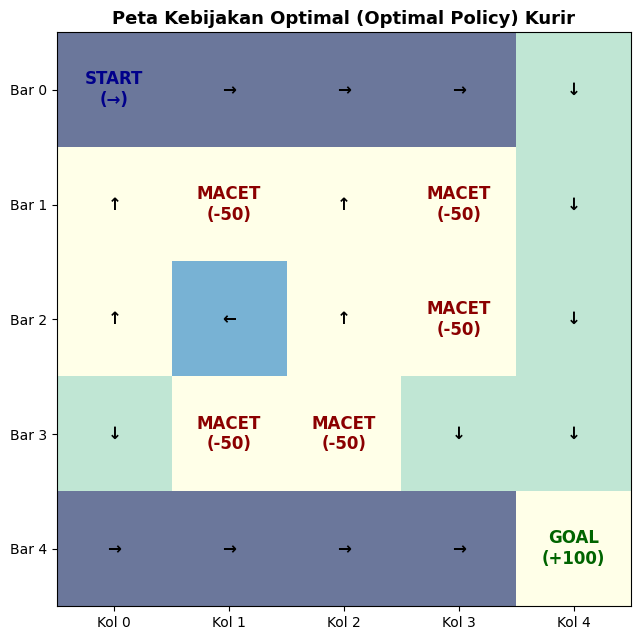

In [22]:
action_symbols = {0: '↑', 1: '↓', 2: '←', 3: '→'}
optimal_actions = np.argmax(q_table_main, axis=1).reshape(5, 5)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.imshow(optimal_actions, cmap='YlGnBu', alpha=0.6)

for r in range(5):
    for c in range(5):
        pos = (r, c)
        if pos == env.start_pos:
            label = f"START\n({action_symbols[optimal_actions[r, c]]})"
            color = 'darkblue'
        elif pos == env.goal_pos:
            label = "GOAL\n(+100)"
            color = 'darkgreen'
        elif pos in env.obstacles:
            label = "MACET\n(-50)"
            color = 'darkred'
        else:
            label = action_symbols[optimal_actions[r, c]]
            color = 'black'

        ax.text(c, r, label, ha='center', va='center', fontsize=12, fontweight='bold', color=color)

ax.set_xticks(np.arange(5))
ax.set_yticks(np.arange(5))
ax.set_xticklabels([f'Kol {i}' for i in range(5)])
ax.set_yticklabels([f'Bar {i}' for i in range(5)])
ax.set_title('Peta Kebijakan Optimal (Optimal Policy) Kurir', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

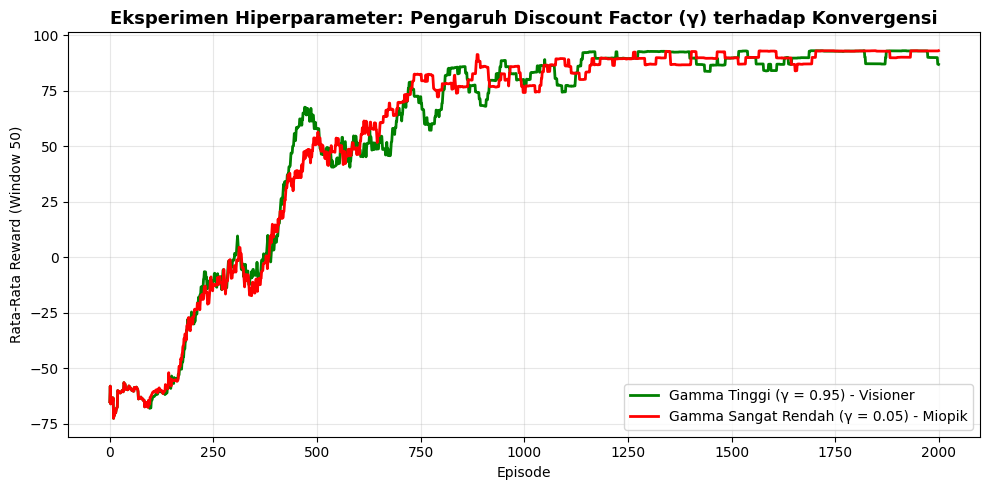

In [23]:
# Eksperimen 1: Discount Factor Tinggi (Gamma = 0.95 -> Agen Visioner)
np.random.seed(42)
_, rewards_gamma_high = train_q_learning(env, alpha=0.8, gamma=0.95, episodes=2000)

# Eksperimen 2: Discount Factor Sangat Rendah (Gamma = 0.05 -> Agen Miopik)
np.random.seed(42)
_, rewards_gamma_low = train_q_learning(env, alpha=0.8, gamma=0.05, episodes=2000)

# Hitung Moving Average keduanya
ma_high = pd.Series(rewards_gamma_high).rolling(window=50, min_periods=1).mean()
ma_low = pd.Series(rewards_gamma_low).rolling(window=50, min_periods=1).mean()

# Plot Perbandingan
plt.figure(figsize=(10, 5))
plt.plot(ma_high, color='green', linewidth=2, label='Gamma Tinggi (γ = 0.95) - Visioner')
plt.plot(ma_low, color='red', linewidth=2, label='Gamma Sangat Rendah (γ = 0.05) - Miopik')
plt.title('Eksperimen Hiperparameter: Pengaruh Discount Factor (γ) terhadap Konvergensi', fontsize=13, fontweight='bold')
plt.xlabel('Episode')
plt.ylabel('Rata-Rata Reward (Window 50)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()